# 02. 수율 예측 ML — 고정 30분 제거 및 시간순 반복 검증
Revision v1 | 2026-11-25

- 기존 Code 13, 17, 23을 유지하여 비교한다. 전체 25개 제품은 별도 적용성 검토 대상으로 둔다.
- 예측 시점: 현재 배치의 첫 로그 시각(생산 시작의 대리값). 원료 검사 결과와 과거 수율의 실제 공개 시각은 확인되지 않아 조건부 PoC로 평가한다.
- 현재 배치 센서, 최종 수행시간, 최종 공정 집계, 30분 필터를 사용하지 않는다.
- 공통 시간 경계를 사용하고 경계를 가로지르는 배치는 해당 분할에서 제외한다. 이전 배치 수율은 완료 시각 + 가정한 공개 지연이 현재 시작보다 엄격히 앞서는 경우만 사용한다.
- 기존 Test는 이미 분석된 자료이므로 독립 외부 검증이 아니다. 검증 기간 내 모델 비교 기준은 제품별 MAE의 단순 평균(macro MAE), Test로 모델을 선택하지 않는다.
- 과거 수율은 평가 기간에 실제 이전 배치가 완료된 후 갱신되는 순차 예측을 가정한다. 모델 파라미터는 각 학습 기간에 고정한다.

In [1]:
from pathlib import Path
import sys, hashlib, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data'/'Laboratory.csv').is_file()), None)
assert ROOT is not None, 'yield_experiment 프로젝트에서 실행하세요.'
DATA = ROOT/'data'
AUDIT = ROOT/'results'/'revision_20261125'/'01_batch_audit_v2'/'batch_duration_audit.csv'
OUT = ROOT/'results'/'revision_20261125'/'02_yield_ml'
OUT.mkdir(parents=True, exist_ok=True)
KEY = ['batch','code']; CODES = [13,17,23]; SEED = 42
OUTER_TRAIN_SHARE = .60
HISTORY_DELAY_MIN = 0  # 실제 수율 공개 지연 미확인: 민감도 실험 시 60, 1440 등 별도 변경
CV_START_FRACTIONS = [.4,.6,.8]  # 기존 Train 내부에서 3회 expanding window
RAW = ['size','api_water','api_total_impurities','api_l_impurity','api_content','api_ps01','api_ps05','api_ps09','lactose_water','lactose_sieve0045','lactose_sieve015','lactose_sieve025','smcc_water','smcc_td','smcc_bd','smcc_ps01','smcc_ps05','smcc_ps09','starch_ph','starch_water']
LAGS = [f'lag{i}' for i in range(1,9)]
assert HISTORY_DELAY_MIN >= 0
assert AUDIT.is_file(), '01_batch_data_analysis v2를 먼저 실행하세요.'
paths = [DATA/'Laboratory.csv', DATA/'Process.csv', DATA/'Process.zip', AUDIT]
hashes = {}
for p in paths:
    with p.open('rb') as f: hashes[p.name] = hashlib.file_digest(f,'sha256').hexdigest()
print('Notebook 02 v1 | no fixed 30-minute features')
print('Root:', ROOT, '\nOutput:', OUT)
print('Python:', sys.version.split()[0], 'pandas:', pd.__version__, 'numpy:', np.__version__, 'sklearn:', sklearn.__version__)
display(pd.Series(hashes,name='SHA256').to_frame())

Notebook 02 v1 | no fixed 30-minute features
Root: /Users/park-inki/Desktop/SKALA-yield-model/yield_experiment 
Output: /Users/park-inki/Desktop/SKALA-yield-model/yield_experiment/results/revision_20261125/02_yield_ml
Python: 3.12.14 pandas: 2.2.3 numpy: 2.3.5 sklearn: 1.8.0


,SHA256
Laboratory.csv,a3b0f16c7c3fa8052b38d767e38fda731a751acc4ec139...
Process.csv,68382e88104beb679acf66d0ec35177e0880e67c7a3d7e...
Process.zip,8a401f1c7ac9880c763e3350f595c45c90487c0950db48...
batch_duration_audit.csv,fa3a5ff2fbae1d44c5b9d5c775fa61440d165cfbb64dd6...


## 1. 배치 데이터 결합 및 학습 범위 확인
01 v2의 로그 시각 결과와 Laboratory 원본을 배치/제품 키로 결합한다. 수행시간은 품질 점검 및 분할 진단에만 사용한다.

In [2]:
lab = pd.read_csv(DATA/'Laboratory.csv', sep=';')
log = pd.read_csv(AUDIT, usecols=KEY+['start_ts','end_ts','campaign','campaign_n','duration_min'])
assert set(KEY+RAW+['tbl_yield']).issubset(lab.columns), '원료 컬럼 확인 필요'
for frame in [lab,log]:
    assert not frame[KEY].isna().any().any()
    assert not frame.duplicated(KEY).any()
for col in ['start_ts','end_ts']:
    log[col] = pd.to_datetime(log[col], format='mixed', errors='raise')
assert not log[['start_ts','end_ts']].isna().any().any()
assert log.end_ts.ge(log.start_ts).all()
assert lab[KEY].merge(log[KEY],on=KEY,how='outer',indicator=True)['_merge'].eq('both').all()
all_batches = lab[KEY+RAW+['tbl_yield']].merge(log,on=KEY,validate='one_to_one')
for col in RAW+['tbl_yield']:
    all_batches[col] = pd.to_numeric(all_batches[col],errors='coerce').replace([np.inf,-np.inf],np.nan)
# 수율 범위 및 데이터 품질 검증
invalid_yield = all_batches.loc[
    all_batches['tbl_yield'].notna()
    & ~all_batches['tbl_yield'].between(0, 100)
].copy()

print("전체 배치 수:", len(all_batches))
print("수율 결측 배치 수:", all_batches['tbl_yield'].isna().sum())
print("최소 수율:", all_batches['tbl_yield'].min())
print("최대 수율:", all_batches['tbl_yield'].max())
print("수율 범위 초과 배치 수:", len(invalid_yield))

print("\n[수율 범위 초과 배치]")
display(
    invalid_yield[['code', 'batch', 'tbl_yield']]
    .sort_values(['code', 'tbl_yield'])
)

print("\n[제품별 수율 범위 초과 배치 수]")
display(invalid_yield.groupby('code').size())

print("\n[ML 분석 대상 제품의 수율 범위 초과 배치]")
display(
    invalid_yield.loc[
        invalid_yield['code'].isin(CODES),
        ['code', 'batch', 'tbl_yield']
    ]
)

invalid_yield.to_csv(
    OUT / 'invalid_yield_audit.csv',
    index=False
)
coverage = all_batches.groupby('code').tbl_yield.agg(batch_n='size',valid_yield_n='count')
coverage['selected'] = coverage.index.isin(CODES)
coverage.to_csv(OUT/'product_coverage.csv'); display(coverage)
df = all_batches[all_batches.code.isin(CODES)].dropna(subset=['tbl_yield']).sort_values(['end_ts','code','batch']).reset_index(drop=True)
assert set(df.code)==set(CODES)
print('전체 배치:',len(all_batches),'ML 대상:',len(df),'수율 결측 제외:',int(all_batches.code.isin(CODES).sum()-len(df)))

전체 배치 수: 1005
수율 결측 배치 수: 0
최소 수율: 87.973
최대 수율: 100.805
수율 범위 초과 배치 수: 1

[수율 범위 초과 배치]


,code,batch,tbl_yield
742,15,736,100.805



[제품별 수율 범위 초과 배치 수]


code
15    1
dtype: int64


[ML 분석 대상 제품의 수율 범위 초과 배치]


,code,batch,tbl_yield


,batch_n,valid_yield_n,selected
code,,,
1,95,95,False
2,17,17,False
3,16,16,False
4,22,22,False
5,3,3,False
6,2,2,False
7,8,8,False
8,2,2,False
9,4,4,False


전체 배치: 1005 ML 대상: 525 수율 결측 제외: 0


## 2. Feature Engineering — 이전 배치 수율
동일 제품 중 이전에 완료되고 공개 지연을 만족한 배치만 참조한다. 현재 배치의 수율, 종료 시각, 수행시간은 입력에서 제외한다. 원료 특성은 실제 서비스 가용성 확인 전 조건부 후보이다.

In [3]:
df['yield_available_ts'] = df.end_ts + pd.to_timedelta(HISTORY_DELAY_MIN,unit='min')
for col in LAGS: df[col] = np.nan
lag_sources = []
for c,h in df.groupby('code'):
    h = h.sort_values(['yield_available_ts','batch'])
    for idx,r in h.iterrows():
        prior = h.loc[(h.yield_available_ts < r.start_ts) & (h.index != idx)].tail(8).iloc[::-1]
        for k,(j,p) in enumerate(prior.iterrows(),1):
            df.loc[idx,f'lag{k}'] = p.tbl_yield
            lag_sources.append(dict(code=c,batch=r.batch,lag=k,source_batch=p.batch,source_available_ts=p.yield_available_ts,prediction_ts=r.start_ts))
source = pd.DataFrame(lag_sources,columns=['code','batch','lag','source_batch','source_available_ts','prediction_ts'])
assert (source.source_available_ts < source.prediction_ts).all()
assert source.batch.ne(source.source_batch).all()
source.to_csv(OUT/'lag_sources.csv',index=False)
# 고정된 알려진 코드 목록으로 one-hot 생성 (정답/수율 통계를 사용하지 않음)
CODE_COLS = [f'code_{c}' for c in CODES]
for c,col in zip(CODES,CODE_COLS): df[col] = df.code.eq(c).astype(float)
FEATURES = {'raw':CODE_COLS+RAW, 'raw_lag':CODE_COLS+RAW+LAGS}
for cols in FEATURES.values():
    assert not set(['tbl_yield','duration_min','end_ts','start_ts','campaign','batch','yield_available_ts']).intersection(cols)
    assert not any('early_' in x for x in cols)
missing = df.groupby('code')[RAW+LAGS].apply(lambda x:x.isna().mean()).T
missing.to_csv(OUT/'feature_missing_rate.csv'); display(missing.round(3))
feature_policy = pd.DataFrame([{'feature':x,'status':'confirmed identifier' if x in CODE_COLS else 'conditional: prior yield availability' if x in LAGS else 'conditional: pre-batch availability'} for x in FEATURES['raw_lag']])
feature_policy.to_csv(OUT/'feature_policy.csv',index=False)
print('Leakage check: lag sources strictly earlier than prediction time:',len(source))

code,13,17,23
size,0.000,0.000,0.000
api_water,0.107,0.048,0.000
api_total_impurities,0.221,0.087,0.000
api_l_impurity,0.916,0.720,0.000
api_content,0.000,0.010,0.000
api_ps01,0.107,0.048,0.000
api_ps05,0.107,0.048,0.000
api_ps09,0.107,0.048,0.000
lactose_water,0.000,0.000,0.000
lactose_sieve0045,0.000,0.000,0.000


Leakage check: lag sources strictly earlier than prediction time: 4092


## 3. 공통 시간순 분할 및 반복 검증 설계
기존 Train/Test 경계를 재현한다. 학습은 경계 이전에 수율까지 확보된 배치만 사용한다. 검증은 해당 구간에 시작하고 다음 경계 전 종료된 배치만 포함한다. 기존 Train 내부에서 3개 검증 구간을 사용한다. 각 분할의 제품별 수와 제외 수를 기록한다. 제품별 독립 분할은 통합 모델에서 미래 정보가 섞일 수 있어 기본 평가로 사용하지 않는다.

In [4]:
outer_cut = df.end_ts.sort_values().iloc[int(len(df)*OUTER_TRAIN_SHARE)]
outer_train = df.index[df.yield_available_ts.lt(outer_cut)]
outer_test = df.index[df.start_ts.ge(outer_cut)]
assert len(outer_train)>0 and len(outer_test)>0
history = df.loc[outer_train].sort_values(['end_ts','code','batch'])
bounds = [history.end_ts.iloc[int(len(history)*f)] for f in CV_START_FRACTIONS] + [outer_cut]
assert all(a<b for a,b in zip(bounds,bounds[1:])), '분할 경계가 중복됨'
folds = []
for i,(lo,hi) in enumerate(zip(bounds,bounds[1:]),1):
    tr = df.index[df.yield_available_ts.lt(lo)]
    va = df.index[df.start_ts.ge(lo)&df.yield_available_ts.lt(hi)]
    folds.append((f'fold_{i}',tr,va,lo,hi))
splits = folds+[('outer_test',outer_train,outer_test,outer_cut,pd.NaT)]
manifest=[]; split_summary=[]; split_quality=[]; feature_shift=[]
for name,tr,va,lo,hi in splits:
    assert len(tr) and len(va) and not set(tr)&set(va)
    assert df.loc[tr,'yield_available_ts'].lt(lo).all() and df.loc[va,'start_ts'].ge(lo).all()
    assert set(df.loc[tr,'code'])==set(CODES), f'{name}: 학습 제품 누락'
    assert set(df.loc[va,'code'])==set(CODES), f'{name}: 평가 제품 누락; 분할 검토 필요'
    scope = df if pd.isna(hi) else df.loc[df.start_ts.lt(hi)]
    ex = scope.index.difference(tr.union(va))
    for phase,ids in [('train',tr),('eval',va),('excluded',ex)]:
        h=df.loc[ids,KEY+['start_ts','end_ts','yield_available_ts','campaign','tbl_yield']].copy()
        h['split']=name; h['phase']=phase; manifest.append(h)
    split_summary.append(dict(split=name,cutoff=lo,eval_end=hi,train_n=len(tr),eval_n=len(va),excluded_n=len(ex)))
    for c in CODES:
        a=df.loc[tr].query('code == @c'); b=df.loc[va].query('code == @c'); q=a.tbl_yield.quantile(.1)
        ca=set(a.campaign.dropna()); cb=set(b.campaign.dropna())
        for phase,h,denom in [('train',a,len(tr)),('eval',b,len(va))]:
            split_quality.append(dict(split=name,code=c,phase=phase,n=len(h),composition_pct=100*len(h)/denom,yield_mean=h.tbl_yield.mean(),yield_std=h.tbl_yield.std(),yield_min=h.tbl_yield.min(),yield_median=h.tbl_yield.median(),duration_median=h.duration_min.median(),train_q10=q,low_n=int(h.tbl_yield.lt(q).sum()),low_rate=h.tbl_yield.lt(q).mean(),campaign_n=h.campaign.nunique(),shared_campaign_n=len(ca&cb)))
        for col in RAW+LAGS:
            s,t=a[col],b[col]; denom=np.sqrt((s.var()+t.var())/2)
            feature_shift.append(dict(split=name,code=c,feature=col,train_missing=s.isna().mean(),eval_missing=t.isna().mean(),train_mean=s.mean(),eval_mean=t.mean(),smd=(t.mean()-s.mean())/denom if pd.notna(denom) and denom>0 else np.nan))
pd.concat(manifest).to_csv(OUT/'split_manifest.csv',index=False)
ss=pd.DataFrame(split_summary); sq=pd.DataFrame(split_quality); fs=pd.DataFrame(feature_shift)
ss.to_csv(OUT/'split_summary.csv',index=False); sq.to_csv(OUT/'split_quality.csv',index=False); fs.to_csv(OUT/'feature_shift.csv',index=False)
display(ss); display(sq.round(3))
print('Campaign 공유는 동일 생산 조건 의존 가능성을 점검하기 위한 지표이며 그 자체로 누수를 확정하지 않는다.')
print('SMD는 분포 차이 진단용이며 통과 기준이 아니다. 분산이 0인 경우 NaN으로 표시.')
display(fs.loc[fs.smd.abs().ge(.5)].sort_values('smd',key=lambda x:x.abs(),ascending=False).head(20))

,split,cutoff,eval_end,train_n,eval_n,excluded_n
0,fold_1,2020-01-07 20:32:00,2020-03-07 18:04:00,126,62,2
1,fold_2,2020-03-07 18:04:00,2020-07-04 10:47:00,189,62,3
2,fold_3,2020-07-04 10:47:00,2020-10-19 02:16:00,252,61,3
3,outer_test,2020-10-19 02:16:00,NaT,315,209,1


,split,code,phase,n,composition_pct,yield_mean,yield_std,yield_min,yield_median,duration_median,train_q10,low_n,low_rate,campaign_n,shared_campaign_n
0,fold_1,13,train,32,25.397,99.168,0.283,98.338,99.147,1027.0,98.921,4,0.125,5,0
1,fold_1,13,eval,9,14.516,99.132,0.328,98.532,99.242,1042.0,98.921,3,0.333,3,0
2,fold_1,17,train,38,30.159,98.766,0.786,96.021,99.101,541.5,97.711,4,0.105,5,1
3,fold_1,17,eval,28,45.161,98.662,0.649,96.875,98.840,539.0,97.711,3,0.107,7,1
4,fold_1,23,train,56,44.444,98.610,0.724,95.592,98.744,529.0,97.748,6,0.107,8,0
5,fold_1,23,eval,25,40.323,98.512,0.557,97.064,98.532,527.0,97.748,3,0.120,4,0
6,fold_2,13,train,42,22.222,99.136,0.325,98.157,99.147,1031.5,98.825,5,0.119,9,1
7,fold_2,13,eval,11,17.742,97.768,1.012,95.261,97.734,857.0,98.825,10,0.909,2,1
8,fold_2,17,train,66,34.921,98.722,0.728,96.021,98.982,540.5,97.702,7,0.106,11,4
9,fold_2,17,eval,29,46.774,98.668,0.806,95.691,98.864,542.0,97.702,4,0.138,8,4


Campaign 공유는 동일 생산 조건 의존 가능성을 점검하기 위한 지표이며 그 자체로 누수를 확정하지 않는다.
SMD는 분포 차이 진단용이며 통과 기준이 아니다. 분산이 0인 경우 NaN으로 표시.


,split,code,feature,train_missing,eval_missing,train_mean,eval_mean,smd
97,fold_2,13,smcc_td,0.000000,0.000000,0.449524,0.430000,-8.946933
241,fold_3,23,smcc_ps09,0.000000,0.000000,260.251330,269.813739,3.276073
185,fold_3,13,smcc_ps09,0.000000,0.000000,260.751852,268.365600,2.634713
98,fold_2,13,smcc_bd,0.000000,0.000000,0.330476,0.310000,-2.525472
93,fold_2,13,lactose_sieve0045,0.000000,0.000000,16.904762,18.727273,2.353701
31,fold_1,17,api_l_impurity,0.789474,0.214286,0.058750,0.075455,2.206151
102,fold_2,13,starch_ph,0.000000,0.000000,4.533333,4.400000,-1.976047
232,fold_3,23,lactose_water,0.000000,0.000000,0.054854,0.072174,1.863883
7,fold_1,13,api_ps09,0.000000,0.000000,171.368437,204.891111,1.845239
158,fold_2,23,starch_ph,0.000000,0.000000,4.551852,4.413636,-1.841928


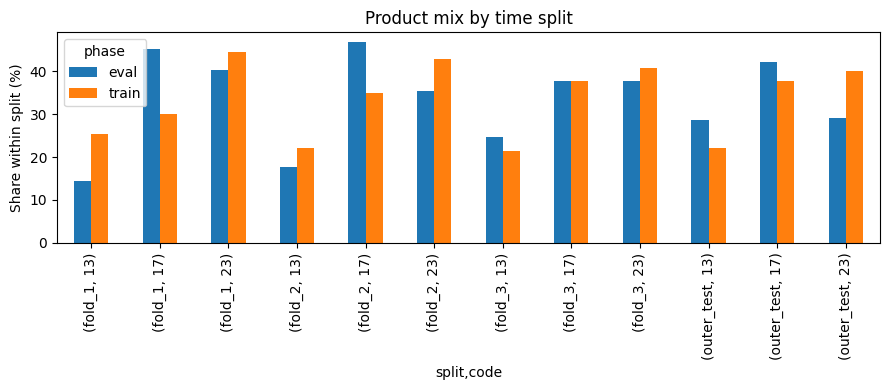

/var/folders/sz/7h8pkgnn6mx8mzsdz06t8bzr0000gn/T/ipykernel_96685/1704075302.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(vals,labels=labels); ax.set(ylabel='Yield (%)',title='Outer split yield distribution'); fig.tight_layout(); fig.savefig(OUT/'outer_yield_distribution.png',dpi=150); plt.show()


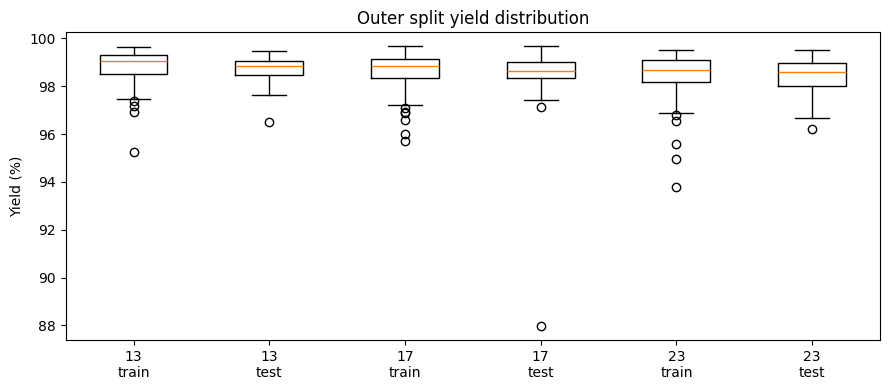

In [5]:
fig, ax = plt.subplots(figsize=(9,4))
sq.pivot(index=['split','code'],columns='phase',values='composition_pct').plot.bar(ax=ax)
ax.set(ylabel='Share within split (%)',title='Product mix by time split'); fig.tight_layout(); fig.savefig(OUT/'split_composition.png',dpi=150); plt.show()
fig,ax=plt.subplots(figsize=(9,4))
vals=[]; labels=[]
for c in CODES:
    for phase,ids in [('train',outer_train),('test',outer_test)]:
        vals.append(df.loc[ids].query('code == @c').tbl_yield); labels.append(f'{c}\n{phase}')
ax.boxplot(vals,labels=labels); ax.set(ylabel='Yield (%)',title='Outer split yield distribution'); fig.tight_layout(); fig.savefig(OUT/'outer_yield_distribution.png',dpi=150); plt.show()

## 4. 모델 학습 및 기준 모델 비교
ProductMedian: 학습 기간 동일 제품 수율 중앙값. LastYield: 예측 시점 이전 가장 최근 수율, 없으면 학습 제품 중앙값. RF와 GB는 원료만 / 원료+과거 수율 두 경우를 비교한다. 결측치 대체는 각 학습 구간에서만 fit 한다. 모델 파라미터는 기존 설정을 사용하고 과도한 튜닝은 하지 않는다.

In [6]:
def build_model(name, seed=SEED):
    if name=='RF':
        model=RandomForestRegressor(n_estimators=200,min_samples_leaf=5,random_state=seed,n_jobs=1)
    elif name=='GB':
        model=GradientBoostingRegressor(n_estimators=100,max_depth=2,min_samples_leaf=5,random_state=seed)
    else: raise ValueError(name)
    return make_pipeline(SimpleImputer(strategy='median',keep_empty_features=True),model)

def score_predictions(h):
    y=h.actual.to_numpy(); p=h.prediction.to_numpy(); err=p-y; low=h.actual.lt(h.train_q10); alert=h.prediction.lt(h.train_q10)
    tp=int((low&alert).sum()); fp=int((~low&alert).sum()); fn=int((low&~alert).sum())
    return dict(n=len(h),mae=mean_absolute_error(y,p),rmse=mean_squared_error(y,p)**.5,r2=r2_score(y,p) if len(h)>1 and np.var(y)>0 else np.nan,bias=err.mean(),low_n=int(low.sum()),low_mae=float(np.abs(err[low]).mean()) if low.any() else np.nan,alert_n=int(alert.sum()),tp=tp,fp=fp,fn=fn,precision=tp/(tp+fp) if tp+fp else np.nan,recall=tp/(tp+fn) if tp+fn else np.nan)

def evaluate(name,tr,va,seed=SEED):
    a=df.loc[tr]; b=df.loc[va]; med=b.code.map(a.groupby('code').tbl_yield.median()); q=b.code.map(a.groupby('code').tbl_yield.quantile(.1))
    predictions={'ProductMedian':med.to_numpy(),'LastYield':b.lag1.fillna(med).to_numpy()}
    for mode,cols in FEATURES.items():
        for alg in ['RF','GB']:
            pipe=build_model(alg,seed).fit(a[cols],a.tbl_yield)
            predictions[f'{alg}_{mode}']=pipe.predict(b[cols])
    rows=[]; detail=[]
    for model,p in predictions.items():
        h=pd.DataFrame({'split':name,'seed':seed,'model':model,'batch':b.batch,'code':b.code,'actual':b.tbl_yield,'prediction':p,'train_q10':q,'prediction_ts':b.start_ts}).reset_index(drop=True)
        detail.append(h)
        rows.append(dict(split=name,seed=seed,model=model,code='ALL',**score_predictions(h)))
        for c,g in h.groupby('code'):
            rows.append(dict(split=name,seed=seed,model=model,code=str(c),**score_predictions(g)))
    return pd.DataFrame(rows),pd.concat(detail,ignore_index=True)

# 모델 비교는 먼저 CV에서만 실행한다.
metrics=[]; predictions=[]
for name,tr,va,_,_ in folds:
    m,p=evaluate(name,tr,va); metrics.append(m); predictions.append(p)
cv=pd.concat(metrics,ignore_index=True); cv_pred=pd.concat(predictions,ignore_index=True)
cv.to_csv(OUT/'cv_metrics.csv',index=False); cv_pred.to_csv(OUT/'cv_predictions.csv',index=False)
macro=cv.query("code != 'ALL'").groupby(['split','model']).mae.mean().rename('macro_mae').reset_index()
cv_all=cv.query("code == 'ALL'").merge(macro,on=['split','model'],validate='one_to_one')
summary=cv_all.groupby('model').agg(folds=('split','nunique'),mae_mean=('mae','mean'),mae_std=('mae','std'),macro_mae_mean=('macro_mae','mean'),macro_mae_std=('macro_mae','std'),rmse_mean=('rmse','mean'),rmse_std=('rmse','std'),r2_mean=('r2','mean'),low_n=('low_n','sum'),tp=('tp','sum'),fp=('fp','sum'),fn=('fn','sum')).sort_values('macro_mae_mean')
summary['pooled_low_recall']=summary.tp/(summary.tp+summary.fn).replace(0,np.nan)
summary.to_csv(OUT/'cv_summary.csv'); display(summary.round(4))
selected=summary.index[0]
print('CV macro MAE 기준 선정:',selected,'(단순 기준 모델도 선택 가능)')
display(cv_all[['split','model','n','mae','macro_mae','rmse','low_n','tp','fn']].round(4))

,folds,mae_mean,mae_std,macro_mae_mean,macro_mae_std,rmse_mean,rmse_std,r2_mean,low_n,tp,fp,fn,pooled_low_recall
model,,,,,,,,,,,,,
RF_raw_lag,3,0.5843,0.1299,0.5815,0.1508,0.8409,0.2170,-0.0731,38,12,3,26,0.3158
RF_raw,3,0.6001,0.1194,0.6034,0.1481,0.8492,0.2262,-0.0922,38,4,4,34,0.1053
ProductMedian,3,0.6169,0.1626,0.6353,0.2010,0.9217,0.2512,-0.2831,38,0,0,38,0.0000
GB_raw,3,0.6613,0.1004,0.6504,0.1504,0.9151,0.1813,-0.3055,38,8,5,30,0.2105
GB_raw_lag,3,0.6547,0.1524,0.6659,0.2243,0.9361,0.2196,-0.3491,38,3,3,35,0.0789
LastYield,3,0.7359,0.1799,0.7012,0.1772,1.0479,0.2944,-0.6675,38,15,26,23,0.3947


CV macro MAE 기준 선정: RF_raw_lag (단순 기준 모델도 선택 가능)


,split,model,n,mae,macro_mae,rmse,low_n,tp,fn
0,fold_1,ProductMedian,62,0.4447,0.4046,0.6527,9,0,9
1,fold_1,LastYield,62,0.5932,0.5245,0.7918,9,3,6
2,fold_1,RF_raw,62,0.4692,0.4357,0.6010,9,2,7
3,fold_1,GB_raw,62,0.5471,0.4945,0.7104,9,2,7
4,fold_1,RF_raw_lag,62,0.4486,0.4074,0.6115,9,3,6
5,fold_1,GB_raw_lag,62,0.4788,0.4290,0.6851,9,2,7
6,fold_2,ProductMedian,62,0.6381,0.7731,0.9624,15,0,15
7,fold_2,LastYield,62,0.6764,0.7003,0.9825,15,9,6
8,fold_2,RF_raw,62,0.6281,0.7163,0.9027,15,2,13
9,fold_2,GB_raw,62,0.7358,0.7947,0.9796,15,6,9


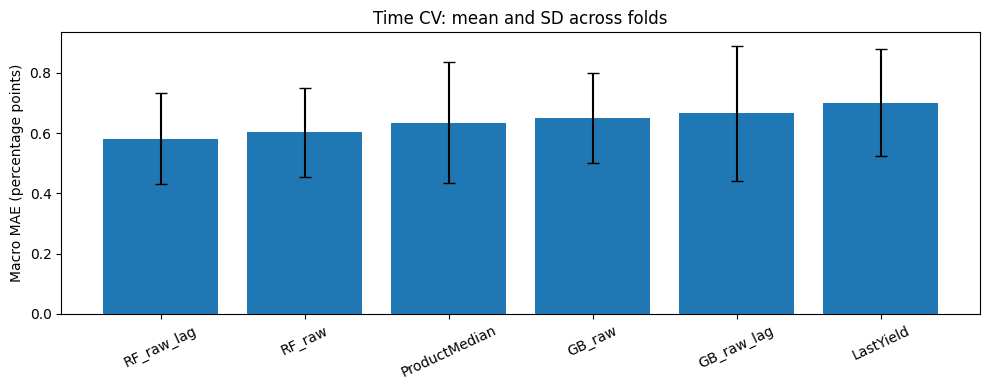

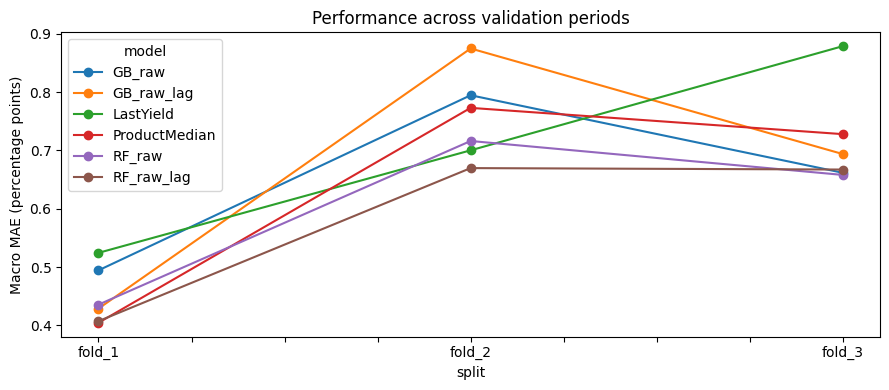

In [7]:
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(summary.index,summary.macro_mae_mean,yerr=summary.macro_mae_std,capsize=4)
ax.set(ylabel='Macro MAE (percentage points)',title='Time CV: mean and SD across folds'); ax.tick_params(axis='x',rotation=25); fig.tight_layout(); fig.savefig(OUT/'cv_macro_mae.png',dpi=150); plt.show()
fig,ax=plt.subplots(figsize=(9,4))
macro.pivot(index='split',columns='model',values='macro_mae').plot(marker='o',ax=ax)
ax.set(ylabel='Macro MAE (percentage points)',title='Performance across validation periods'); fig.tight_layout(); fig.savefig(OUT/'cv_fold_mae.png',dpi=150); plt.show()

## 5. Seed 민감도 및 고정 Seed 재현성
동일한 시간 분할에서 RF/GB의 seed를 7, 42, 123으로 변경하여 CV 결과 변동을 확인한다. 동일 seed로 모델을 다시 학습하는 재현성 확인과 다른 기간 성능 검증은 별개의 항목이다.

In [8]:
seed_rows=[cv]
for seed in [7,123]:
    for name,tr,va,_,_ in folds:
        m,_=evaluate(name,tr,va,seed=seed); seed_rows.append(m)
seed_metrics=pd.concat(seed_rows,ignore_index=True)
seed_macro=seed_metrics.query("code != 'ALL'").groupby(['split','seed','model']).mae.mean().reset_index(name='macro_mae')
seed_summary=seed_macro.groupby(['model','seed']).macro_mae.mean().unstack('seed')
seed_summary['range']=seed_summary.max(axis=1)-seed_summary.min(axis=1)
seed_macro.to_csv(OUT/'seed_metrics.csv',index=False); seed_summary.to_csv(OUT/'seed_summary.csv'); display(seed_summary.round(5))
_,tr,va,_,_=folds[-1]
repeat=[]
for mode,cols in FEATURES.items():
    for alg in ['RF','GB']:
        a=build_model(alg).fit(df.loc[tr,cols],df.loc[tr,'tbl_yield']).predict(df.loc[va,cols])
        b=build_model(alg).fit(df.loc[tr,cols],df.loc[tr,'tbl_yield']).predict(df.loc[va,cols])
        diff=float(np.max(np.abs(a-b)))
        repeat.append(dict(model=f'{alg}_{mode}',seed=SEED,max_abs_difference=diff,match=bool(np.allclose(a,b,rtol=0,atol=1e-12))))
repro=pd.DataFrame(repeat); repro.to_csv(OUT/'determinism_check.csv',index=False); display(repro)
assert repro.match.all(), '동일 seed 재학습 결과 불일치' 

seed,7,42,123,range
model,,,,
GB_raw,0.64716,0.65035,0.65038,0.00322
GB_raw_lag,0.66593,0.66593,0.66612,0.00019
LastYield,0.70125,0.70125,0.70125,0.00000
ProductMedian,0.63527,0.63527,0.63527,0.00000
RF_raw,0.60070,0.60338,0.60809,0.00739
RF_raw_lag,0.58245,0.58153,0.58604,0.00451


,model,seed,max_abs_difference,match
0,RF_raw,42,0.0,True
1,GB_raw,42,0.0,True
2,RF_raw_lag,42,0.0,True
3,GB_raw_lag,42,0.0,True


## 6. 기존 Test 구간 평가 (독립 검증 아님)
CV에서 선정한 후보를 명시하고 이전에 사용했던 평가 기간에서 비교한다. 전체 MAE/RMSE뿐 아니라 제품별 MAE와 가상 저수율 기준 하회 사례도 보고한다. Q10은 학습 데이터에서만 계산하고 실제 승인 규격이 아니다. 양성 사례 수가 작으면 recall을 일반화하지 않는다.

,split,seed,code,n,mae,rmse,r2,bias,low_n,low_mae,alert_n,tp,fp,fn,precision,recall,macro_mae,cv_selected
model,,,,,,,,,,,,,,,,,,
ProductMedian,outer_test,42,ALL,209,0.5330,1.0005,-0.1072,0.3270,17,2.1386,0,0,0,17,NaN,0.0000,0.5254,False
LastYield,outer_test,42,ALL,209,0.5786,0.9757,-0.0530,0.0411,17,1.5188,18,5,13,12,0.2778,0.2941,0.5560,False
RF_raw,outer_test,42,ALL,209,0.5879,1.0063,-0.1201,-0.0270,17,1.7288,0,0,0,17,NaN,0.0000,0.5837,False
GB_raw,outer_test,42,ALL,209,0.6639,1.0636,-0.2515,-0.1522,17,1.6723,10,0,10,17,0.0000,0.0000,0.6635,False
RF_raw_lag,outer_test,42,ALL,209,0.5194,0.9484,0.0050,0.0027,17,1.7230,0,0,0,17,NaN,0.0000,0.5098,True
GB_raw_lag,outer_test,42,ALL,209,0.5737,0.9817,-0.0662,-0.0630,17,1.6817,3,0,3,17,0.0000,0.0000,0.5647,False


,code,model,n,mae,rmse,low_n,low_mae,tp,fn,recall
1,13,ProductMedian,60,0.4444,0.6577,5,1.5888,0,5,0.0000
2,17,ProductMedian,88,0.5813,1.3007,5,3.3456,0,5,0.0000
3,23,ProductMedian,61,0.5507,0.7506,7,1.6693,0,7,0.0000
5,13,LastYield,60,0.3768,0.5391,5,0.4216,2,3,0.4000
6,17,LastYield,88,0.7238,1.2882,5,2.7848,1,4,0.2000
7,23,LastYield,61,0.5675,0.7629,7,1.3983,2,5,0.2857
9,13,RF_raw,60,0.4946,0.6402,5,0.8559,0,5,0.0000
10,17,RF_raw,88,0.6133,1.3007,5,3.1374,0,5,0.0000
11,23,RF_raw,61,0.6432,0.7909,7,1.3462,0,7,0.0000
13,13,GB_raw,60,0.5329,0.6652,5,0.9417,0,5,0.0000


,split,seed,model,batch,code,actual,prediction,train_q10,prediction_ts,abs_error
846,outer_test,42,RF_raw_lag,789,17,87.973,98.583299,97.6046,2020-10-27 14:01:00,10.610299
938,outer_test,42,RF_raw_lag,903,23,96.216,98.323197,97.5605,2021-02-15 06:43:00,2.107197
902,outer_test,42,RF_raw_lag,851,13,96.506,98.421752,97.8150,2021-01-21 12:01:00,1.915752
933,outer_test,42,RF_raw_lag,889,23,96.679,98.454880,97.5605,2021-02-05 13:49:00,1.775880
937,outer_test,42,RF_raw_lag,902,23,96.792,98.434418,97.5605,2021-02-14 22:34:00,1.642418
984,outer_test,42,RF_raw_lag,956,17,97.112,98.568331,97.6046,2021-04-02 17:09:00,1.456331
868,outer_test,42,RF_raw_lag,811,23,97.154,98.441060,97.5605,2020-11-22 22:32:00,1.287060
1004,outer_test,42,RF_raw_lag,987,23,97.448,98.605001,97.5605,2021-04-21 08:50:00,1.157001
949,outer_test,42,RF_raw_lag,910,13,97.857,99.013100,97.8150,2021-02-19 14:18:00,1.156100
985,outer_test,42,RF_raw_lag,958,17,99.620,98.482744,97.6046,2021-04-06 15:43:00,1.137256


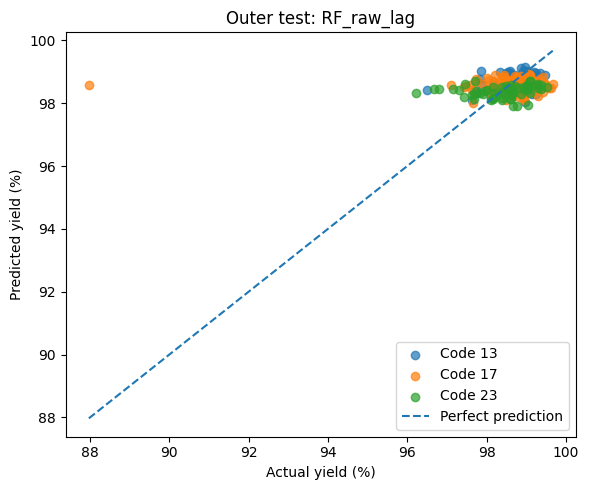

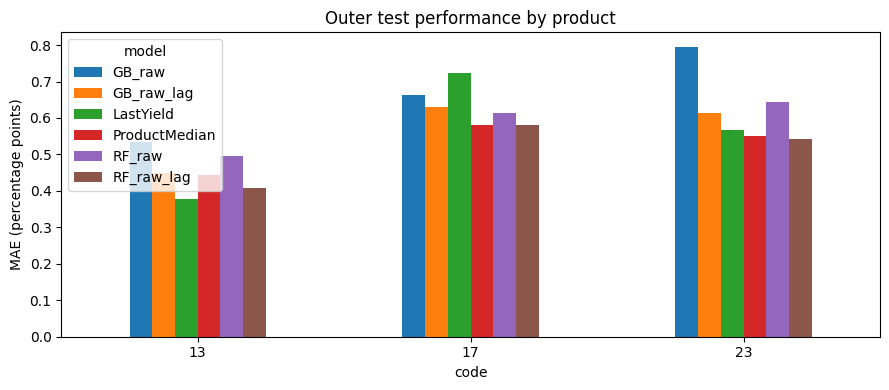

In [9]:
test_metrics,test_pred=evaluate('outer_test',outer_train,outer_test)
test_metrics.to_csv(OUT/'outer_metrics.csv',index=False); test_pred.to_csv(OUT/'outer_predictions.csv',index=False)
test_macro=test_metrics.query("code != 'ALL'").groupby('model').mae.mean().rename('macro_mae')
outer_summary=test_metrics.query("code == 'ALL'").set_index('model').join(test_macro)
outer_summary['cv_selected']=outer_summary.index==selected
outer_summary.to_csv(OUT/'outer_summary.csv'); display(outer_summary.round(4))
display(test_metrics.query("code != 'ALL'")[['code','model','n','mae','rmse','low_n','low_mae','tp','fn','recall']].round(4))
focus=test_pred.loc[test_pred.model.eq(selected)].copy(); focus['abs_error']=(focus.actual-focus.prediction).abs()
display(focus.sort_values('abs_error',ascending=False).head(10))
fig,ax=plt.subplots(figsize=(6,5))
for c,h in focus.groupby('code'): ax.scatter(h.actual,h.prediction,label=f'Code {c}',alpha=.7)
lo=min(focus.actual.min(),focus.prediction.min()); hi=max(focus.actual.max(),focus.prediction.max()); ax.plot([lo,hi],[lo,hi],'--',label='Perfect prediction'); ax.set(xlabel='Actual yield (%)',ylabel='Predicted yield (%)',title=f'Outer test: {selected}'); ax.legend(); fig.tight_layout(); fig.savefig(OUT/'outer_actual_vs_predicted.png',dpi=150); plt.show()
fig,ax=plt.subplots(figsize=(9,4))
test_metrics.query("code != 'ALL'").pivot(index='code',columns='model',values='mae').plot.bar(ax=ax,rot=0)
ax.set(ylabel='MAE (percentage points)',title='Outer test performance by product'); fig.tight_layout(); fig.savefig(OUT/'outer_mae_by_product.png',dpi=150); plt.show()

In [10]:
meta={'revision':'02_v1','python':sys.version,'pandas':pd.__version__,'numpy':np.__version__,'sklearn':sklearn.__version__,'hashes':hashes,'seed':SEED,'seed_checks':[7,42,123],'codes':CODES,'history_delay_min':HISTORY_DELAY_MIN,'outer_cut':str(outer_cut),'cv_start_fractions':CV_START_FRACTIONS,'features':FEATURES,'model_params':{alg:build_model(alg)[-1].get_params() for alg in ['RF','GB']},'selection_metric':'mean fold macro MAE','cv_selected':selected,'outer_test_previously_seen':True,'availability_status':'conditional research PoC','prediction_mode':'rolling one-batch ahead; past observed outcomes only','q10_status':'exploratory, not approved specification'}
(OUT/'metadata.json').write_text(json.dumps(meta,ensure_ascii=False,indent=2),encoding='utf-8')
print('Results:',OUT)
print('Completed: 02_v1')

Results: /Users/park-inki/Desktop/SKALA-yield-model/yield_experiment/results/revision_20261125/02_yield_ml
Completed: 02_v1


## 7. 결과 해석 (실행 후 작성)
- 제품별 구성 및 수율 분포 차이, 주요 입력변수 결측/분포 차이, Campaign 공유 여부
- CV 평균/표준편차와 단순 모델 대비 개선 여부, seed 민감도
- 기존 평가 구간 전체/제품별 성능 및 저수율 사례 누락
- 서비스에서 원료 및 과거 수율의 공개 시점 확인 전에는 운영 가능 여부 확정 불가
- 다음 단계: 실제 서비스 데이터 계약 확인, 필요시 공개 지연 민감도 및 제품 범위 확대, 통계적 탐지(I-MR/Nelson/가상 규격) 별도 설계. SHAP은 선정 모델 및 입력 가용성 확정 후 검토한다.

## 8. 추가 검증: 결측 변수 및 수율 확인 지연 (v2)
기존 v1 결과를 유지한다. 고정된 검증 배치/시간 경계에서 RF를 비교한다. 0/60/1440분은 가정이며 실제 공개 시각은 미확인이다. 학습 데이터는 해당 경계까지 수율이 공개된 배치만 사용하며, 평가 배치는 동일하게 유지한다. 같은 평가 구간 내 과거 배치 수율은 공개 시점 이후에만 참조하는 rolling one-batch-ahead 방식이다. 제품별 중앙값과 과거 수율을 사용하지 않는 RF를 지연별로 함께 비교한다. 결측률 50% 기준과 api_l_impurity 지정 제외는 탐색적이며, 최종 선택은 기존 Train 내부 CV만 활용한다. 기존 Test는 이미 관찰한 데이터이므로 독립 검증이 아니다.

In [11]:
# 8-1. 실험 설정 및 지연별 과거 수율 생성
SENS_OUT = OUT.parent / '02_yield_ml_sensitivity'
SENS_OUT.mkdir(parents=True, exist_ok=True)
DELAYS = [0, 60, 1440]
MISSING_LIMIT = 0.50
assert HISTORY_DELAY_MIN == 0, '기존 비교 기준은 지연 0분이어야 합니다.'
assert 'api_l_impurity' in RAW
assert df.tbl_yield.between(0, 100).all(), 'ML 대상 수율 범위 재확인 필요'

def make_delayed_history(minutes):
    h = df.copy()
    h['yield_available_ts'] = h.end_ts + pd.Timedelta(minutes=minutes)
    h[LAGS] = np.nan
    refs = []
    for c, g in h.groupby('code'):
        g = g.sort_values(['yield_available_ts', 'batch'])
        for idx, r in g.iterrows():
            prior = g.loc[(g.yield_available_ts < r.start_ts) & (g.index != idx)].tail(len(LAGS)).iloc[::-1]
            for k, (j, prev) in enumerate(prior.iterrows(), 1):
                h.loc[idx, f'lag{k}'] = prev.tbl_yield
                refs.append(dict(delay_min=minutes, code=c, batch=r.batch, lag=k, source_batch=prev.batch, source_available_ts=prev.yield_available_ts, prediction_ts=r.start_ts))
    refs = pd.DataFrame(refs, columns=['delay_min','code','batch','lag','source_batch','source_available_ts','prediction_ts'])
    assert refs.source_available_ts.lt(refs.prediction_ts).all()
    assert refs.batch.ne(refs.source_batch).all()
    return h, refs

delayed = {}; ref_tables = []; coverage_rows = []
for delay in DELAYS:
    h, refs = make_delayed_history(delay)
    delayed[delay] = h; ref_tables.append(refs)
    for c, g in h.groupby('code'):
        coverage_rows.append(dict(delay_min=delay, code=c, n=len(g), lag1_available_n=g.lag1.notna().sum(), lag1_available_rate=g.lag1.notna().mean(), all8_available_rate=g[LAGS].notna().all(axis=1).mean()))
assert np.allclose(delayed[0][LAGS], df[LAGS], equal_nan=True), '기존 lag 재현 불일치'
pd.concat(ref_tables, ignore_index=True).to_csv(SENS_OUT/'lag_sources_by_delay.csv', index=False)
lag_coverage = pd.DataFrame(coverage_rows)
lag_coverage.to_csv(SENS_OUT/'lag_availability.csv', index=False)
display(lag_coverage.round(4))

,delay_min,code,n,lag1_available_n,lag1_available_rate,all8_available_rate
0,0,13,131,130,0.9924,0.9389
1,0,17,207,206,0.9952,0.9614
2,0,23,187,186,0.9947,0.9572
3,60,13,131,130,0.9924,0.9313
4,60,17,207,206,0.9952,0.9614
5,60,23,187,186,0.9947,0.9572
6,1440,13,131,130,0.9924,0.9237
7,1440,17,207,206,0.9952,0.9517
8,1440,23,187,186,0.9947,0.9572


In [12]:
# 8-2. 동일 평가 배치로 비교하는 함수
# Q10은 각 고정 원본 학습 집합에서 계산한 비교용 기준으로 고정한다.
# 지연 조건에 따라 실제 학습 집합이 줄어들어도 평가 라벨이 달라지지 않도록 한다.
# 이 Q10은 평가 전용이며, 실제 운영 경보용으로 쓰려면 공개된 학습 수율만으로 재산출해야 한다.
POLICIES = ['all', 'drop_api_l_impurity', 'drop_high_missing']

def sensitivity_split(split, original_tr, va, cutoff, delay, policies=POLICIES, include_baselines=True, include_no_lag=True):
    h = delayed[delay]
    tr = original_tr.intersection(h.index[h.yield_available_ts.lt(cutoff)])
    a, b = h.loc[tr], h.loc[va]
    assert not set(tr) & set(va)
    assert a.yield_available_ts.lt(cutoff).all() and b.start_ts.ge(cutoff).all()
    assert set(a.code) == set(b.code) == set(CODES), f'{split}/{delay}: 제품 학습 이력 부족'
    med = b.code.map(a.groupby('code').tbl_yield.median())
    q = b.code.map(df.loc[original_tr].groupby('code').tbl_yield.quantile(.1))
    by_code_missing = a.groupby('code')[RAW].apply(lambda x: x.isna().mean())
    high = [col for col in RAW if by_code_missing[col].gt(MISSING_LIMIT).any()]
    drops = {'all': [], 'drop_api_l_impurity': ['api_l_impurity'], 'drop_high_missing': high}
    rows=[]; details=[]; configs=[]; fit_predictions={}
    def add(model, policy, p, cols, removed):
        z = pd.DataFrame(dict(split=split,delay_min=delay,model=model,policy=policy,batch=b.batch,code=b.code,actual=b.tbl_yield,prediction=p,train_q10=q)).reset_index(drop=True)
        details.append(z)
        for label, group in [('ALL',z), *[(str(c),g) for c,g in z.groupby('code')]]:
            rows.append(dict(split=split,delay_min=delay,model=model,policy=policy,code=label,train_n=len(a),**score_predictions(group)))
        configs.append(dict(split=split,delay_min=delay,model=model,policy=policy,train_n=len(a),eval_n=len(b),removed_features='|'.join(removed),features='|'.join(cols)))
    if include_baselines:
        add('ProductMedian','all',med.to_numpy(),[],[])
        add('LastYield','all',b.lag1.fillna(med).to_numpy(),['lag1'],[])
    for policy in policies:
        removed = drops[policy]; raw = [x for x in RAW if x not in removed]
        for model, cols in [('RF_raw_lag',CODE_COLS+raw+LAGS), ('RF_raw',CODE_COLS+raw)]:
            if model=='RF_raw' and not include_no_lag: continue
            key=tuple(cols)
            if key not in fit_predictions:
                fit_predictions[key] = build_model('RF',SEED).fit(a[cols],a.tbl_yield).predict(b[cols])
            add(model,policy,fit_predictions[key],cols,removed)
    return pd.DataFrame(rows),pd.concat(details,ignore_index=True),pd.DataFrame(configs)

def sensitivity_summary(metrics):
    group=['delay_min','model','policy']
    macro=metrics.loc[metrics.code.ne('ALL')].groupby(['split']+group).mae.mean().rename('macro_mae').reset_index()
    a=metrics.loc[metrics.code.eq('ALL')].merge(macro,on=['split']+group,validate='one_to_one')
    s=a.groupby(group).agg(folds=('split','nunique'),mae_mean=('mae','mean'),macro_mae_mean=('macro_mae','mean'),macro_mae_std=('macro_mae','std'),rmse_mean=('rmse','mean'),r2_mean=('r2','mean'),low_n=('low_n','sum'),tp=('tp','sum'),fp=('fp','sum'),fn=('fn','sum'),alert_n=('alert_n','sum')).reset_index()
    s['recall']=s.tp/(s.tp+s.fn).replace(0,np.nan)
    s['precision']=s.tp/(s.tp+s.fp).replace(0,np.nan)
    return s.sort_values(['delay_min','macro_mae_mean','model','policy']).reset_index(drop=True)

In [13]:
# 8-3. 기존 Train 내부 CV: 3개 지연 × 3개 변수 정책
sm=[]; sp=[]; sc=[]; train_manifest=[]
for delay in DELAYS:
    for name,tr,va,lo,hi in folds:
        m,p,c=sensitivity_split(name,tr,va,lo,delay)
        sm.append(m); sp.append(p); sc.append(c)
        a=delayed[delay].loc[tr]
        available=a.yield_available_ts.lt(lo)
        temp=a[KEY+['yield_available_ts']].assign(split=name,delay_min=delay,train_included=available)
        train_manifest.append(temp)
metrics_s=pd.concat(sm,ignore_index=True); pred_s=pd.concat(sp,ignore_index=True); config_s=pd.concat(sc,ignore_index=True)
summary_s=sensitivity_summary(metrics_s)
# 기존 0분/all 결과가 동일한지 확인
for model in ['RF_raw_lag','RF_raw','ProductMedian','LastYield']:
    v=summary_s.query('delay_min == 0 and policy == "all" and model == @model').macro_mae_mean.iloc[0]
    assert np.isclose(v,summary.loc[model,'macro_mae_mean'],rtol=0,atol=1e-10), f'{model}: 기존 CV 재현 실패'
# 모든 조건이 같은 평가 배치와 같은 비교용 Q10 라벨을 사용하는지 검증
assert pred_s.groupby(['split','code','batch']).train_q10.nunique().eq(1).all()
assert metrics_s.query('code == "ALL"').groupby('split').n.nunique().eq(1).all()
metrics_s.to_csv(SENS_OUT/'sensitivity_cv_metrics.csv',index=False)
pred_s.to_csv(SENS_OUT/'sensitivity_cv_predictions.csv',index=False)
config_s.to_csv(SENS_OUT/'sensitivity_feature_manifest.csv',index=False)
pd.concat(train_manifest,ignore_index=True).to_csv(SENS_OUT/'sensitivity_train_manifest.csv',index=False)
summary_s.to_csv(SENS_OUT/'sensitivity_cv_summary.csv',index=False)
print('기존 0분/all 결과 재현 및 동일 평가 배치 확인 완료')
display(summary_s.round(4))
display(config_s[['split','delay_min','policy','train_n','removed_features']].drop_duplicates())

기존 0분/all 결과 재현 및 동일 평가 배치 확인 완료


,delay_min,model,policy,folds,mae_mean,macro_mae_mean,macro_mae_std,rmse_mean,r2_mean,low_n,tp,fp,fn,alert_n,recall,precision
0,0,RF_raw_lag,all,3,0.5843,0.5815,0.1508,0.8409,-0.0731,38,12,3,26,15,0.3158,0.8000
1,0,RF_raw_lag,drop_api_l_impurity,3,0.5846,0.5816,0.1518,0.8413,-0.0740,38,12,3,26,15,0.3158,0.8000
2,0,RF_raw_lag,drop_high_missing,3,0.5846,0.5816,0.1518,0.8413,-0.0740,38,12,3,26,15,0.3158,0.8000
3,0,RF_raw,drop_api_l_impurity,3,0.5985,0.6019,0.1470,0.8464,-0.0853,38,4,4,34,8,0.1053,0.5000
4,0,RF_raw,drop_high_missing,3,0.5985,0.6019,0.1470,0.8464,-0.0853,38,4,4,34,8,0.1053,0.5000
5,0,RF_raw,all,3,0.6001,0.6034,0.1481,0.8492,-0.0922,38,4,4,34,8,0.1053,0.5000
6,0,ProductMedian,all,3,0.6169,0.6353,0.2010,0.9217,-0.2831,38,0,0,38,0,0.0000,NaN
7,0,LastYield,all,3,0.7359,0.7012,0.1772,1.0479,-0.6675,38,15,26,23,41,0.3947,0.3659
8,60,RF_raw_lag,all,3,0.5850,0.5903,0.1431,0.8415,-0.0731,38,7,3,31,10,0.1842,0.7000
9,60,RF_raw_lag,drop_api_l_impurity,3,0.5853,0.5911,0.1459,0.8418,-0.0734,38,5,3,33,8,0.1316,0.6250


,split,delay_min,policy,train_n,removed_features
0,fold_1,0,all,126,
4,fold_1,0,drop_api_l_impurity,126,api_l_impurity
6,fold_1,0,drop_high_missing,126,api_l_impurity
8,fold_2,0,all,189,
12,fold_2,0,drop_api_l_impurity,189,api_l_impurity
14,fold_2,0,drop_high_missing,189,api_l_impurity
16,fold_3,0,all,252,
20,fold_3,0,drop_api_l_impurity,252,api_l_impurity
22,fold_3,0,drop_high_missing,252,api_l_impurity
24,fold_1,60,all,125,


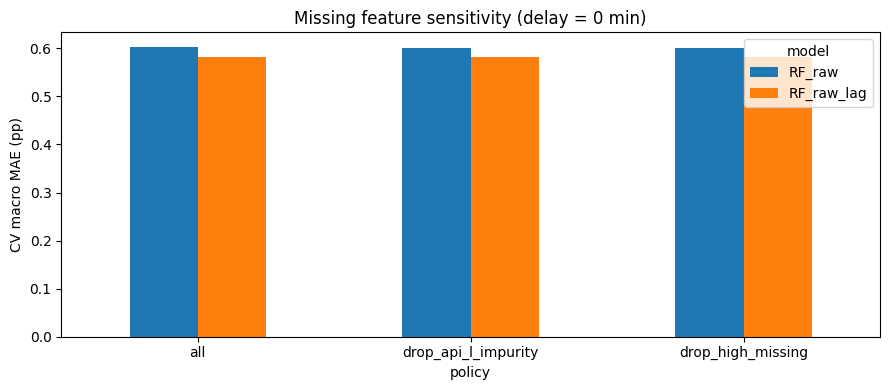

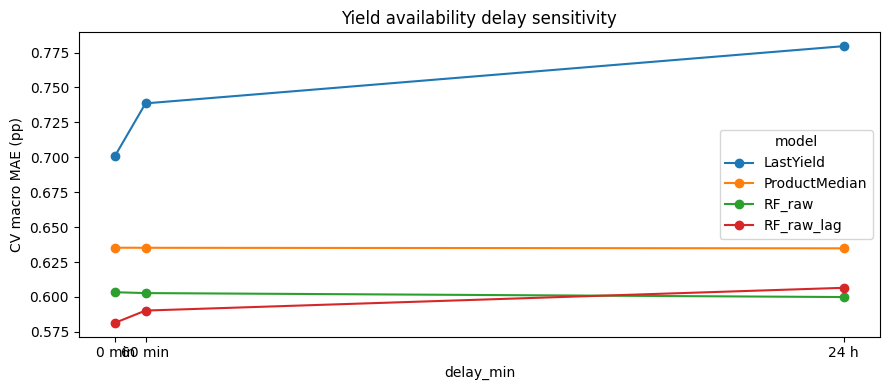

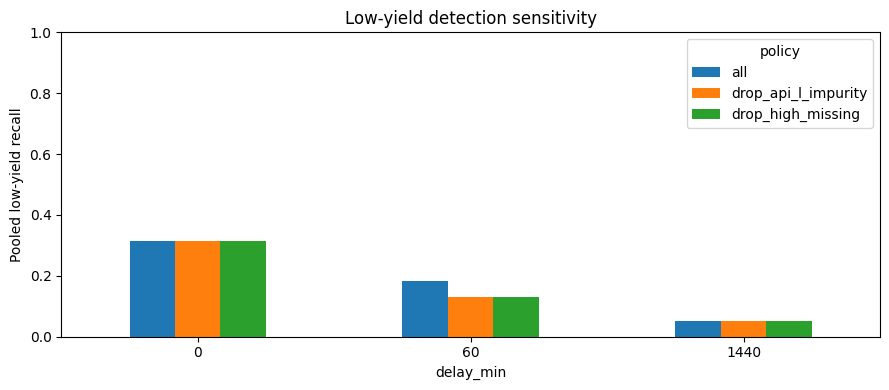

In [14]:
# 8-4. 결측 변수 영향과 지연 영향 시각화
fig,ax=plt.subplots(figsize=(9,4))
view=summary_s.query('delay_min == 0 and model in ["RF_raw_lag","RF_raw"]').pivot(index='policy',columns='model',values='macro_mae_mean')
view.reindex(POLICIES).plot.bar(ax=ax,rot=0)
ax.set(ylabel='CV macro MAE (pp)',title='Missing feature sensitivity (delay = 0 min)'); fig.tight_layout(); fig.savefig(SENS_OUT/'missing_feature_sensitivity.png',dpi=150); plt.show()
fig,ax=plt.subplots(figsize=(9,4))
view=summary_s.query('policy == "all"').pivot(index='delay_min',columns='model',values='macro_mae_mean').reindex(DELAYS)
view.plot(marker='o',ax=ax); ax.set_xticks(DELAYS, ['0 min','60 min','24 h']); ax.set(ylabel='CV macro MAE (pp)',title='Yield availability delay sensitivity'); fig.tight_layout(); fig.savefig(SENS_OUT/'yield_delay_sensitivity.png',dpi=150); plt.show()
fig,ax=plt.subplots(figsize=(9,4))
view=summary_s.query('model == "RF_raw_lag"').pivot(index='delay_min',columns='policy',values='recall').reindex(DELAYS)
view.plot.bar(ax=ax,rot=0); ax.set(ylabel='Pooled low-yield recall',ylim=(0,1),title='Low-yield detection sensitivity'); fig.tight_layout(); fig.savefig(SENS_OUT/'low_yield_recall_sensitivity.png',dpi=150); plt.show()

## 9. 기존 Test 기간 점검 및 선택 기록
각 지연 시나리오에서 CV macro MAE가 가장 작은 후보를 선택한다(단순 기준 모델도 가능). 지연 자체는 성능을 보고 선택하는 옵션이 아니라 서비스에서 실제 확인 가능한 조건으로 결정한다. 기존 Test 기간에는 선택 후보와 제품별 중앙값, 기존 RF(all) 비교 결과를 기록한다. Q10은 이전 학습 기준을 고정한 탐색적 비교용이며 공식 규격이 아니다. 실제 운영 threshold/일탈 분류 검증과는 별개이다.

In [15]:
# 9-1. CV 기준 후보 선정 및 기존 Test 재평가
chosen_s=summary_s.sort_values(['delay_min','macro_mae_mean','model','policy']).groupby('delay_min',as_index=False).first()
chosen_s.to_csv(SENS_OUT/'sensitivity_cv_selected.csv',index=False)
om=[]; op=[]; oc=[]
for delay in DELAYS:
    pick=chosen_s.loc[chosen_s.delay_min.eq(delay)].iloc[0]
    pol=list(dict.fromkeys(['all',pick.policy]))
    m,p,c=sensitivity_split('outer_test',outer_train,outer_test,outer_cut,delay,policies=pol)
    for frame in [m,p,c]:
        frame['cv_selected']=frame.model.eq(pick.model)&frame.policy.eq(pick.policy)
    om.append(m); op.append(p); oc.append(c)
outer_m=pd.concat(om,ignore_index=True); outer_p=pd.concat(op,ignore_index=True); outer_c=pd.concat(oc,ignore_index=True)
outer_m.to_csv(SENS_OUT/'sensitivity_outer_metrics.csv',index=False)
outer_p.to_csv(SENS_OUT/'sensitivity_outer_predictions.csv',index=False)
outer_c.to_csv(SENS_OUT/'sensitivity_outer_manifest.csv',index=False)
outer_s=outer_m.query('code == "ALL"').merge(outer_m.query('code != "ALL"').groupby(['delay_min','model','policy']).mae.mean().rename('macro_mae').reset_index(),on=['delay_min','model','policy'],validate='one_to_one')
outer_s.to_csv(SENS_OUT/'sensitivity_outer_summary.csv',index=False)
focus_s=outer_s.loc[outer_s.cv_selected | outer_s.model.eq('ProductMedian') | (outer_s.model.eq('RF_raw_lag')&outer_s.policy.eq('all'))]
display(chosen_s.round(4)); display(focus_s.round(4))
case=outer_p.loc[outer_p.code.eq(17)&outer_p.batch.eq(789)&(outer_p.cv_selected|(outer_p.model.eq('RF_raw_lag')&outer_p.policy.eq('all')))].copy()
case['abs_error']=(case.actual-case.prediction).abs(); case.to_csv(SENS_OUT/'batch789_sensitivity.csv',index=False); display(case.round(4))
meta_s=dict(revision='02_v2_sensitivity',base_metadata=meta,delays_min=DELAYS,missing_threshold=MISSING_LIMIT,missing_rule='any product in training only',fixed_drop='api_l_impurity (exploratory after inspecting v1)',evaluation='fixed evaluation cohorts; fixed original training Q10 for comparison only',selection='within each delay: CV macro MAE; delay not selected by performance',outer_test_previously_seen=True,actual_availability_unverified=True)
(SENS_OUT/'metadata.json').write_text(json.dumps(meta_s,ensure_ascii=False,indent=2),encoding='utf-8')
print('Completed: 02_v2_sensitivity |', SENS_OUT)

,delay_min,model,policy,folds,mae_mean,macro_mae_mean,macro_mae_std,rmse_mean,r2_mean,low_n,tp,fp,fn,alert_n,recall,precision
0,0,RF_raw_lag,all,3,0.5843,0.5815,0.1508,0.8409,-0.0731,38,12,3,26,15,0.3158,0.8
1,60,RF_raw_lag,all,3,0.5850,0.5903,0.1431,0.8415,-0.0731,38,7,3,31,10,0.1842,0.7
2,1440,RF_raw,drop_api_l_impurity,3,0.5956,0.5988,0.1472,0.8470,-0.0892,38,2,0,36,2,0.0526,1.0


,split,delay_min,model,policy,code,train_n,n,mae,rmse,r2,...,low_n,low_mae,alert_n,tp,fp,fn,precision,recall,cv_selected,macro_mae
0,outer_test,0,ProductMedian,all,ALL,315,209,0.5330,1.0005,-0.1072,...,17,2.1386,0,0,0,17,NaN,0.0,False,0.5254
2,outer_test,0,RF_raw_lag,all,ALL,315,209,0.5194,0.9484,0.0050,...,17,1.7230,0,0,0,17,NaN,0.0,True,0.5098
4,outer_test,60,ProductMedian,all,ALL,315,209,0.5330,1.0005,-0.1072,...,17,2.1386,0,0,0,17,NaN,0.0,False,0.5254
6,outer_test,60,RF_raw_lag,all,ALL,315,209,0.5285,0.9561,-0.0112,...,17,1.7855,0,0,0,17,NaN,0.0,True,0.5227
8,outer_test,1440,ProductMedian,all,ALL,315,209,0.5330,1.0005,-0.1072,...,17,2.1386,0,0,0,17,NaN,0.0,False,0.5254
10,outer_test,1440,RF_raw_lag,all,ALL,315,209,0.5573,0.9795,-0.0613,...,17,1.7833,0,0,0,17,NaN,0.0,False,0.5465
13,outer_test,1440,RF_raw,drop_api_l_impurity,ALL,315,209,0.5866,1.0070,-0.1218,...,17,1.7396,0,0,0,17,NaN,0.0,True,0.5826


,split,delay_min,model,policy,batch,code,actual,prediction,train_q10,cv_selected,abs_error
428,outer_test,0,RF_raw_lag,all,789,17,87.973,98.5833,97.6046,True,10.6103
1264,outer_test,60,RF_raw_lag,all,789,17,87.973,98.6646,97.6046,True,10.6916
2100,outer_test,1440,RF_raw_lag,all,789,17,87.973,98.8160,97.6046,False,10.8430
2727,outer_test,1440,RF_raw,drop_api_l_impurity,789,17,87.973,98.8649,97.6046,True,10.8919


Completed: 02_v2_sensitivity | /Users/park-inki/Desktop/SKALA-yield-model/yield_experiment/results/revision_20261125/02_yield_ml_sensitivity


## 10. 추가 검증 결과 기록 (실행 후 작성)
- 결측 변수 제외 전후 CV macro MAE / 저수율 recall 차이
- 지연별 이전 배치 수율 확보율 및 학습 배치 수 변화
- 단순 기준 대비 개선 여부, 제품별 성능 및 Batch 789 오류
- 원료/과거 수율의 실제 가용 시각 미확인, 기존 Test 재사용, Q10 가상 기준, 검증 구간 3개라는 한계
- 수율 확인 지연은 서비스 데이터 계약으로 정하며 CV 성능으로 지연값을 선정하지 않는다. 이상 예측 성능이 불충분하면 참고용 수율 추정으로 한정한다.